<center><h1>CNN классификации

<h2>Классические сверточные сети

<h3>LeNet

<text>Очень старая НС. Жила в то время, когда если были ресурсы, то не было данных, а ресурсов было ещё меньше. Является 5 версией этой архитектуры (ей 36 лет...). Была основана на биоидеях. В настоящее время её не используют, пытаются уйти от Био.

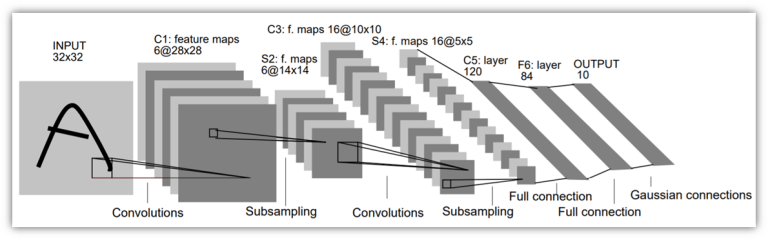

<h3>AlexNet

Чередование свертки и пулинга. Использует ReLU. Имеет много ядер, различной формы. Не полностью сверточная, в конце FCL. 

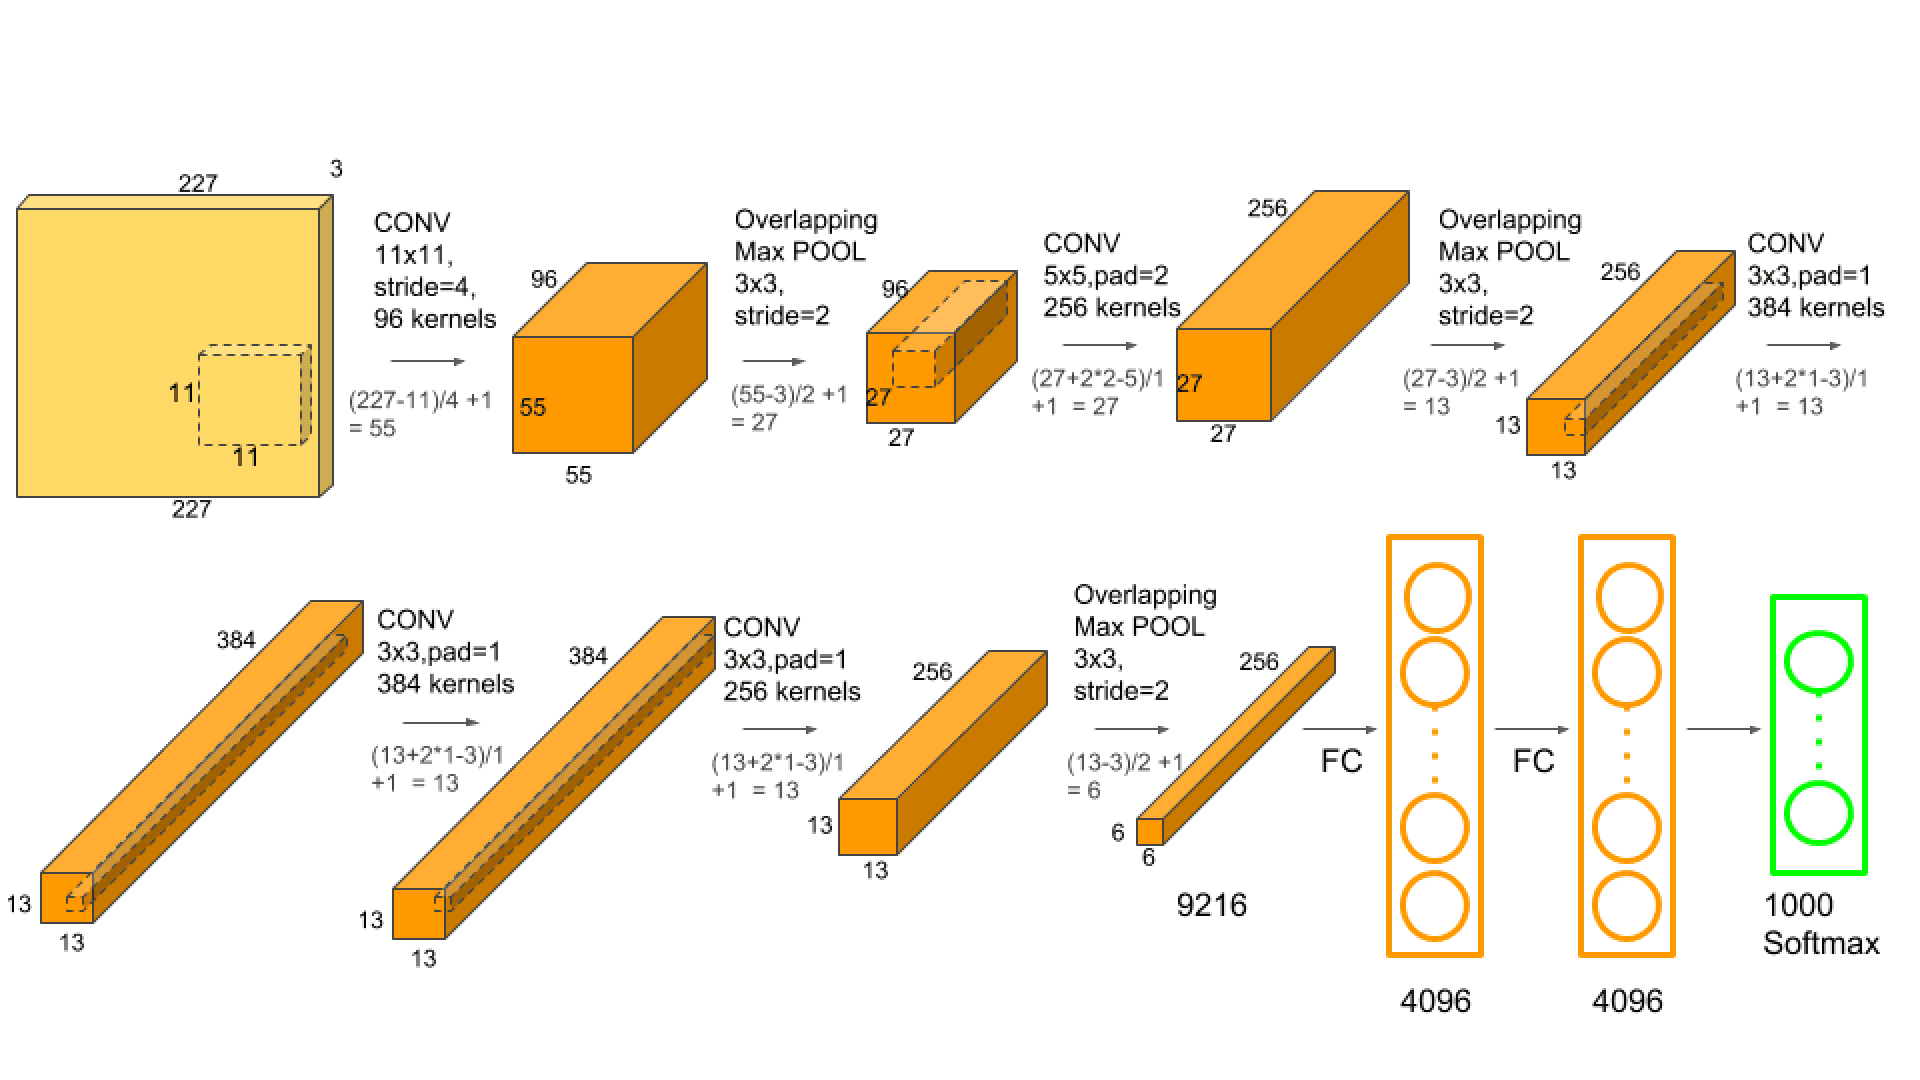
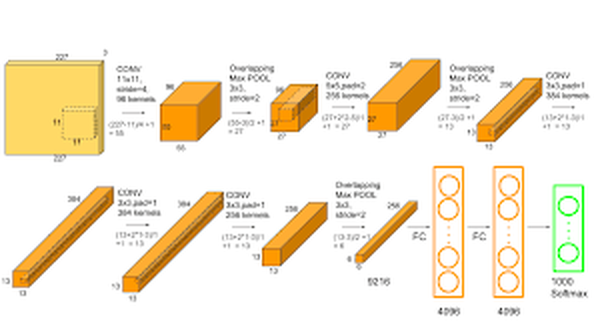
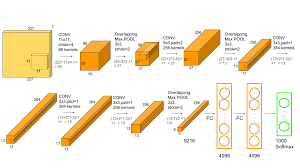

<h3>VGG</h3>

Предназначался для классификации изображений на 1000 классов. На свой момент времени была самой большой (больше слоёв уже не обучались :) )

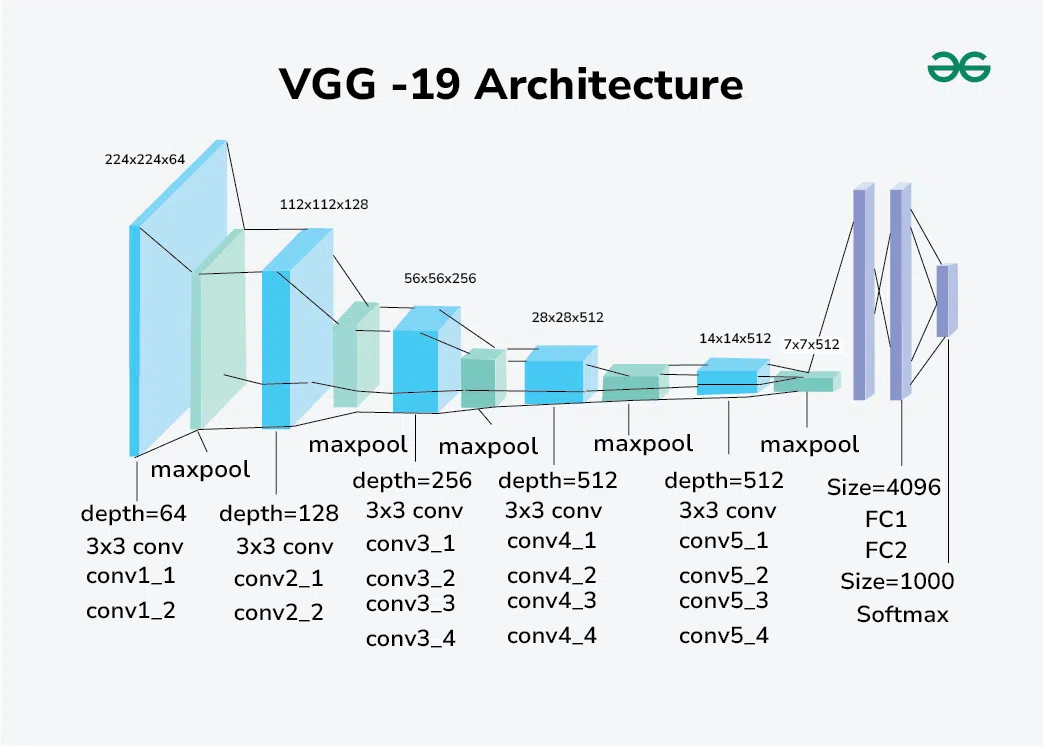

<h3>Nin</h3>

<text>Полностью сверточная сеть<text>

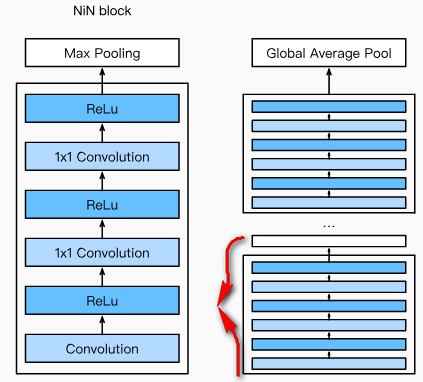

<h3>Inception/GoogleNet

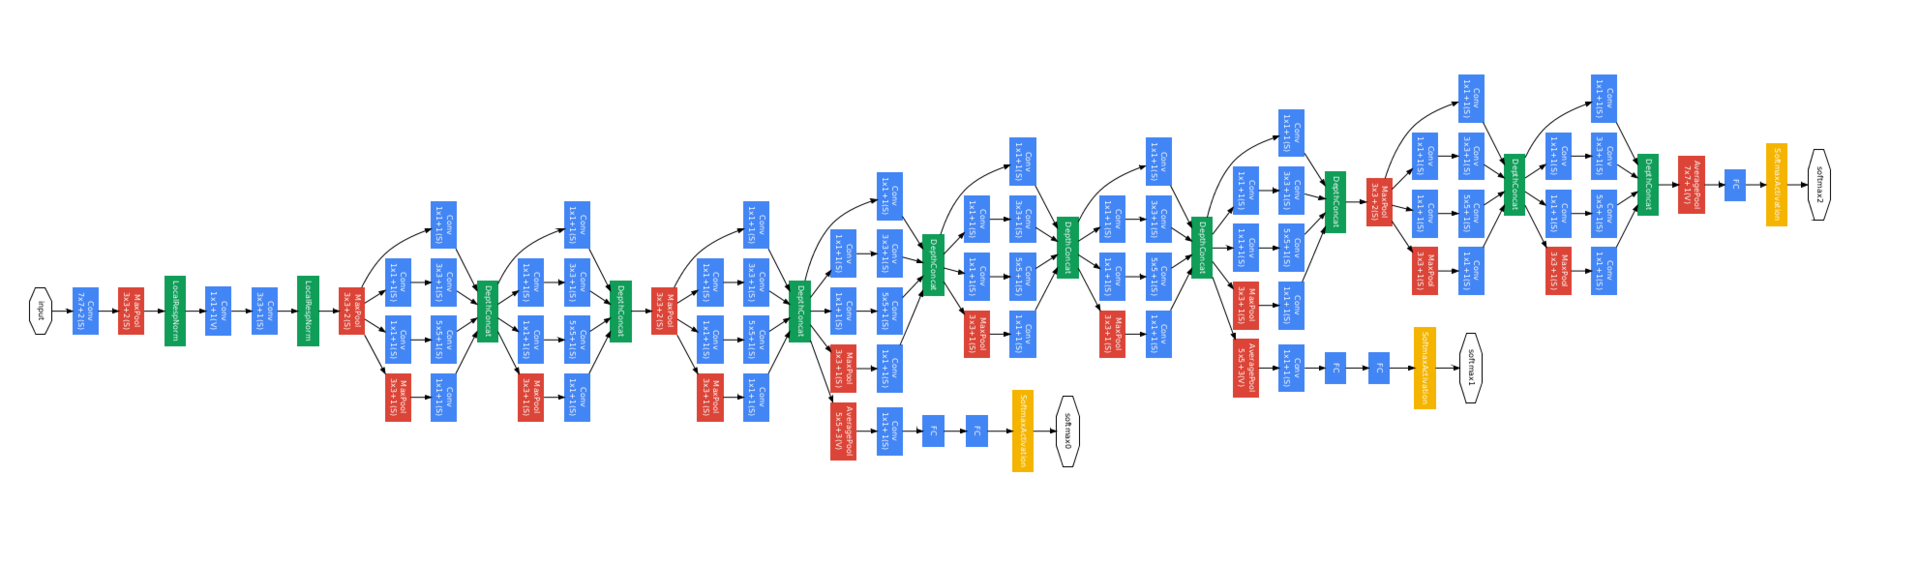

<h3>ResNet</h3>

<text>Основана на пропускающей связи (передаем вход на выход, суммируем их). Самая большая конфигурация - 150 слоев, можно и большее, хоть 1000 слоёв

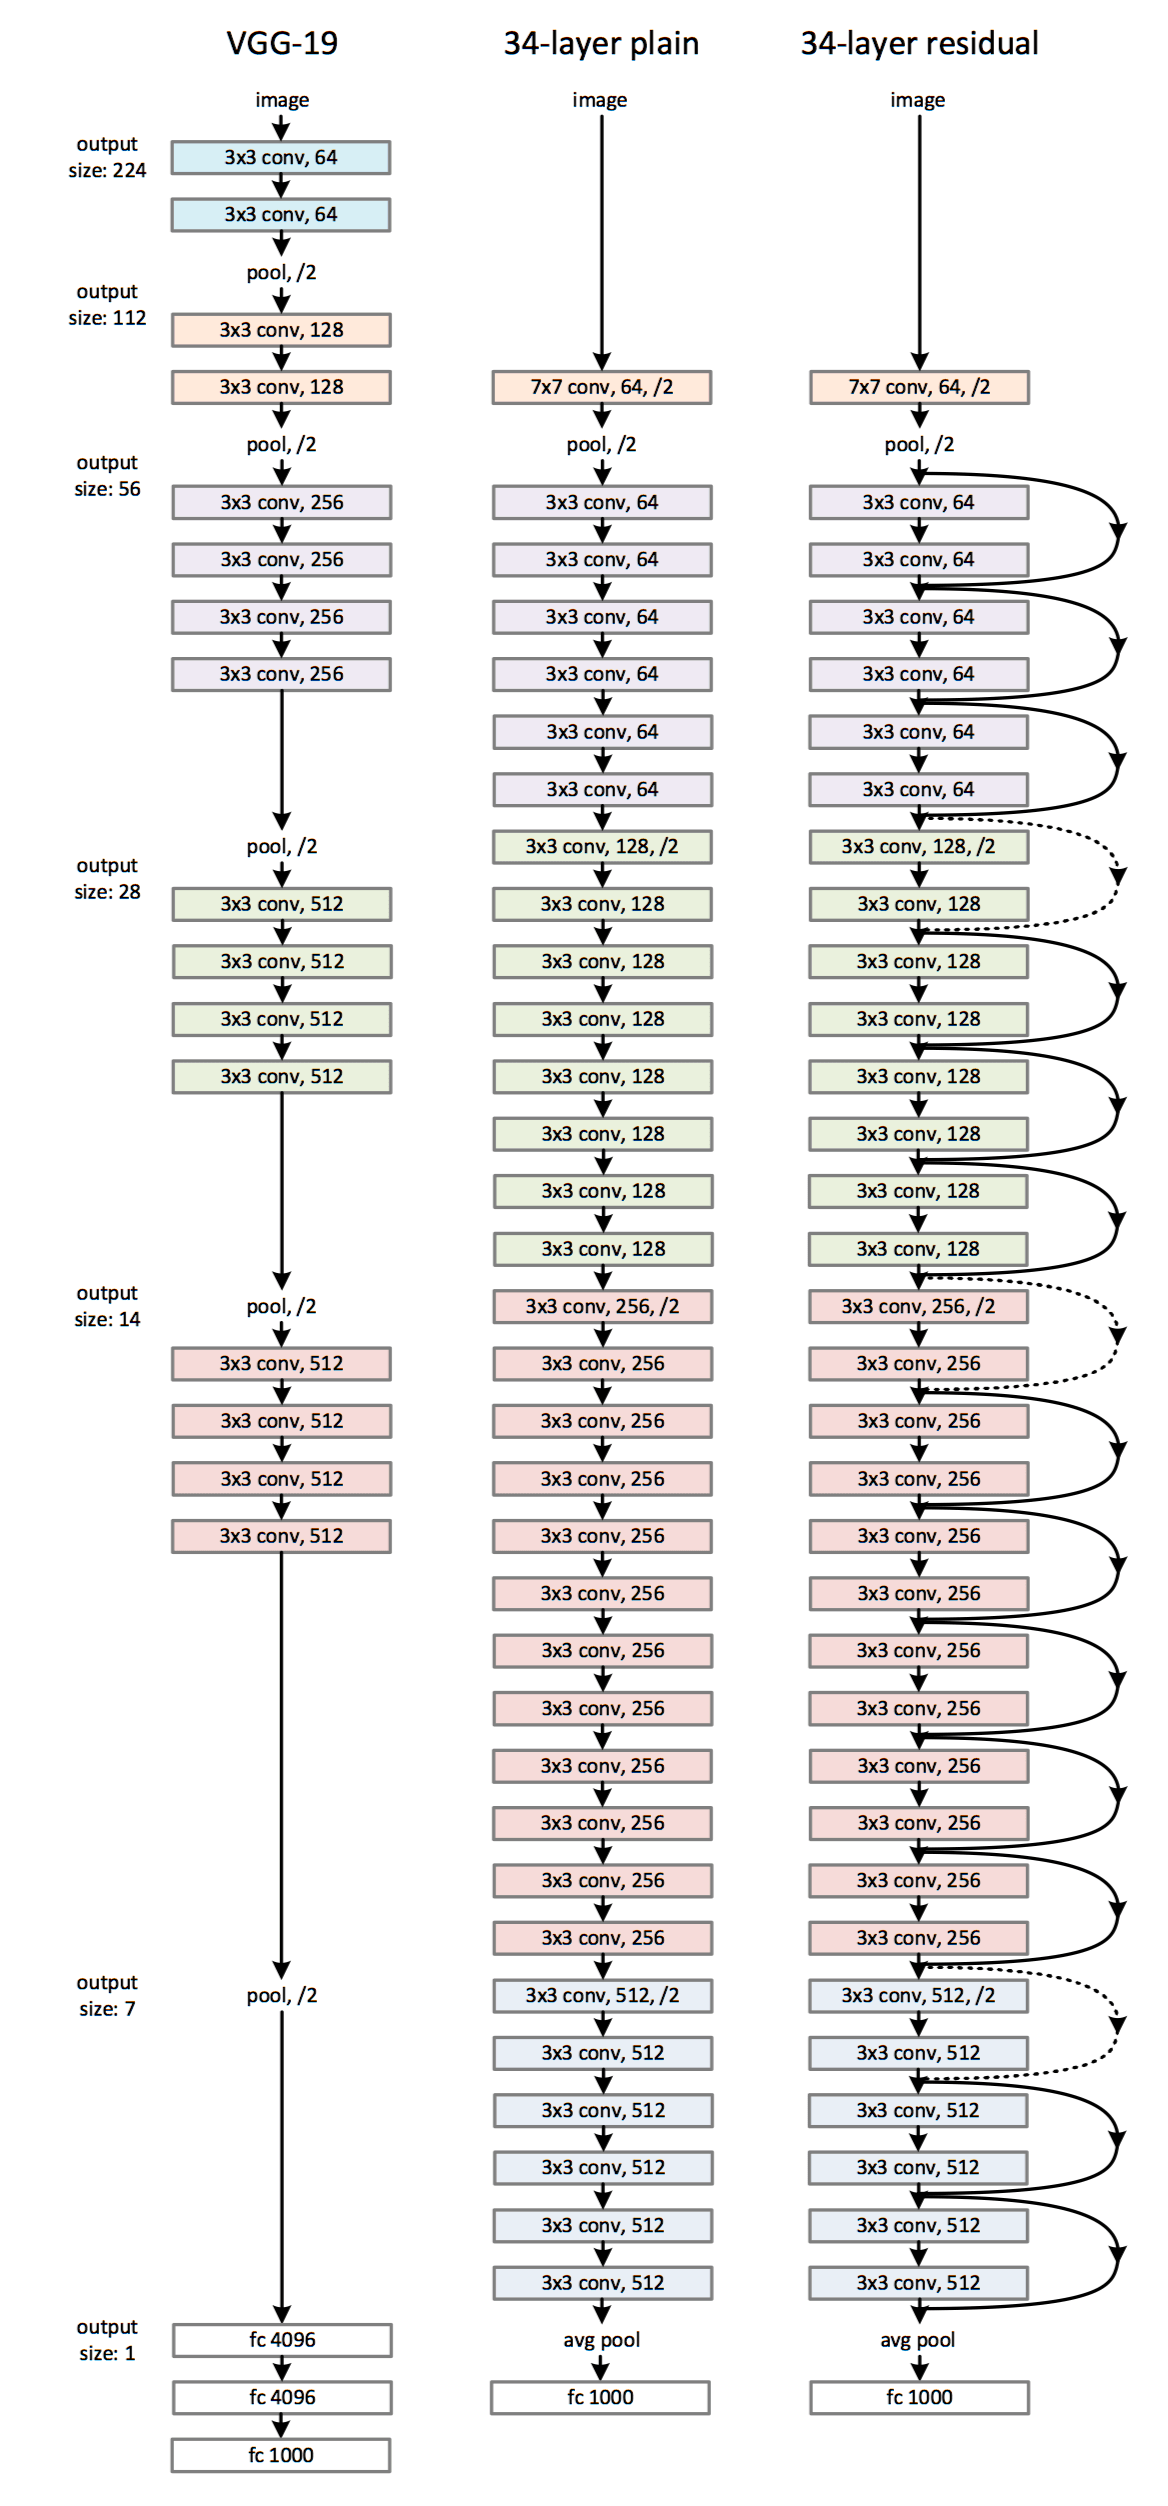

<h2>Загрузка данных

<h3>Аугментация данных

In [1]:
import torch
import torch.nn as nn
import cv2 as cv
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

Проблемы обучения:
1. Мало данных
2. Локализация данных в CNN (если обучались на одном, оно другое не даст: кошка смотрела влево, дали смотрящую вправо, ошибки)

Аугментация данных — изменение изначальных данных и добавление измененных в датасет (блюрить, контурить и т.д)

In [2]:
def load_image(path):
    img = cv.imread(path)[:, :, ::-1]
    # ::-1 чтобы поменять цветные каналы BGR -> RGB
    return img

korgi = load_image('D:\\MIREA\\DPO\\Learning\\Practic2_5\\korkik.jpg')

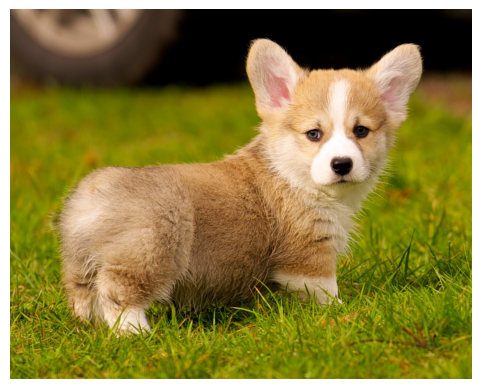

In [3]:
plt.imshow(korgi)
plt.axis('off')
plt.show()

In [4]:
def show_image(img, picture_name):
    plt.imshow(img)
    plt.title(picture_name)
    plt.show()

In [5]:
res_transformation = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(size=(224, 224))
])

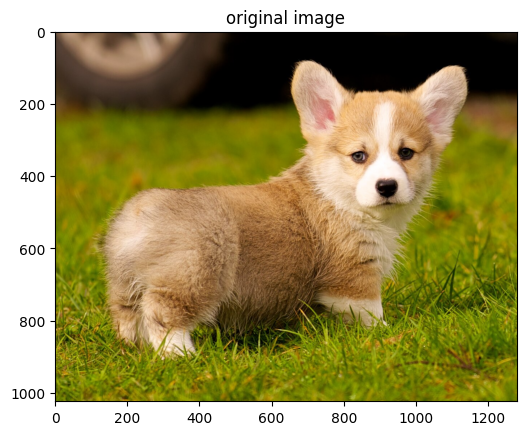

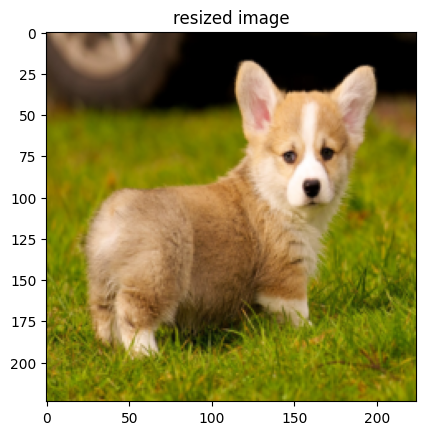

In [6]:
res_img = res_transformation(korgi)
show_image(korgi, 'original image')
show_image(res_img, 'resized image')

In [7]:
horizontal_flip = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(p=1)
])

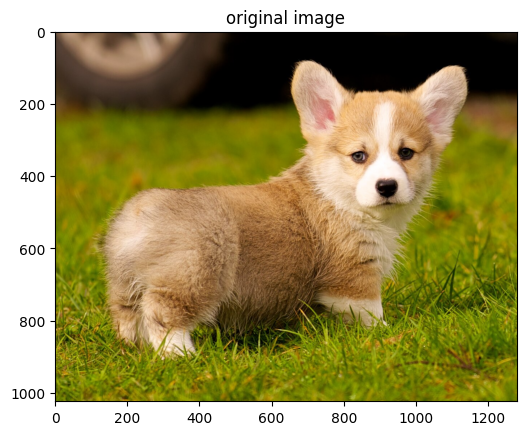

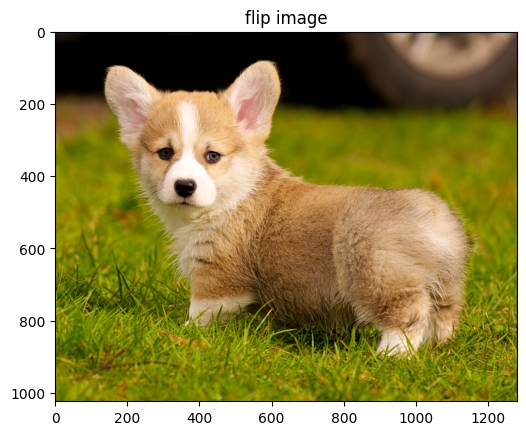

In [8]:
flip_img = horizontal_flip(korgi)
show_image(korgi, 'original image')
show_image(flip_img, 'flip image')

In [9]:
vertical_flip = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomVerticalFlip(p=1)
])

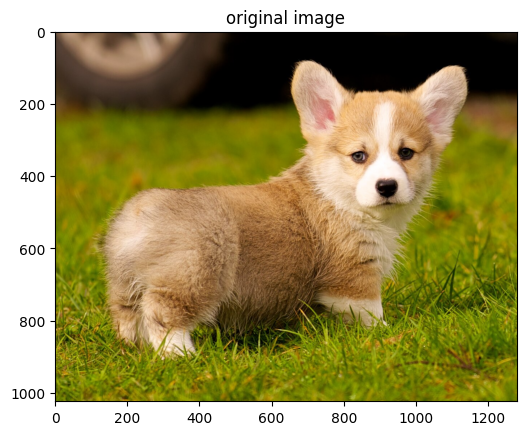

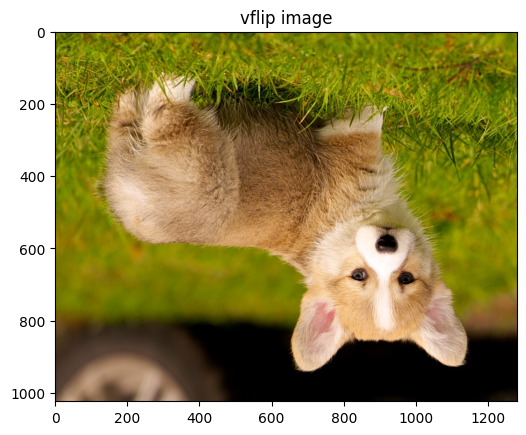

In [10]:
vflip_img = vertical_flip(korgi)
show_image(korgi, 'original image')
show_image(vflip_img, 'vflip image')

In [11]:
color_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ColorJitter(brightness=(.2, .4), contrast=1, saturation=0, hue=.4)
])

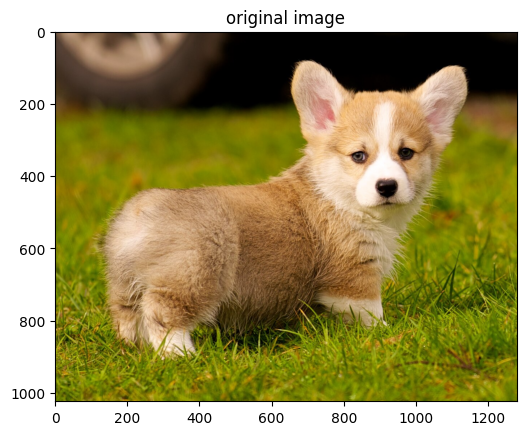

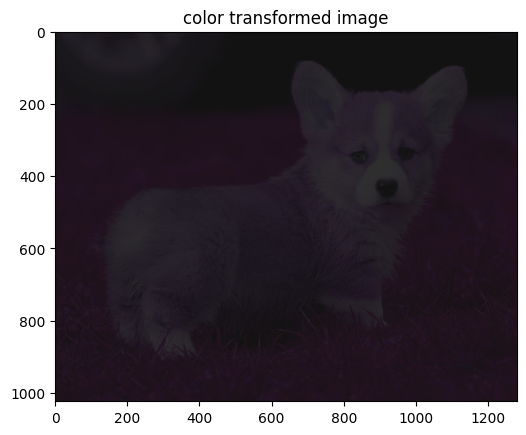

In [12]:
color_img = color_transforms(korgi)
show_image(korgi, 'original image')
show_image(color_img, 'color transformed image')

In [13]:
crop_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(size=(224, 224))
])

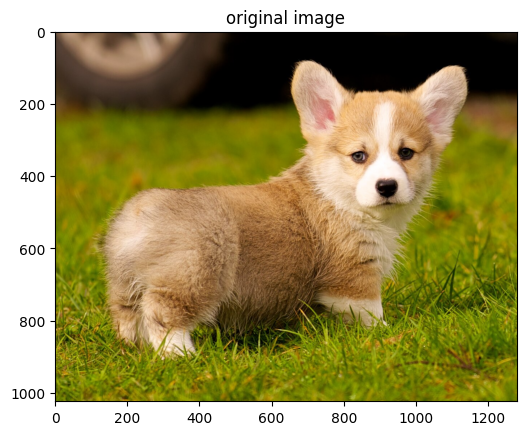

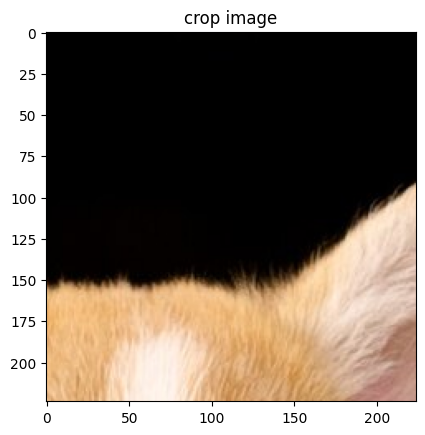

In [14]:
crop_image = crop_transform(korgi)
show_image(korgi, 'original image')
show_image(crop_image, 'crop image')

In [18]:
rotate_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomRotation(degrees=66)
])

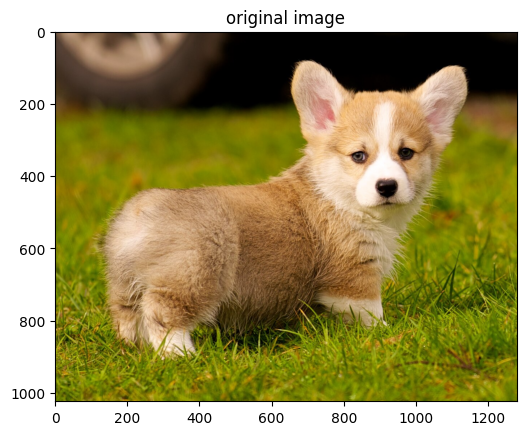

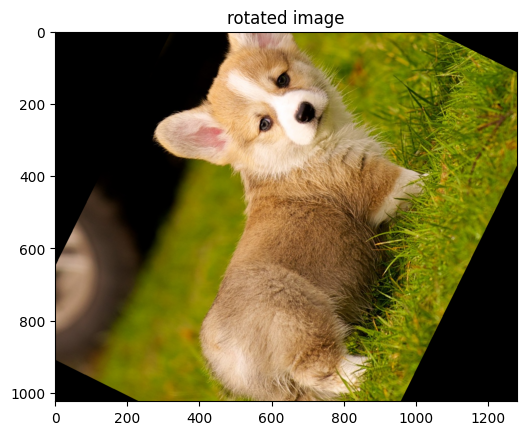

In [22]:
rotate_image = rotate_transform(korgi)
show_image(korgi, 'original image')
show_image(rotate_image, 'rotated image')

In [29]:
norm_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[5, .9, .6], std=[1.45, .21, 7.12]),
    transforms.ToPILImage()
])

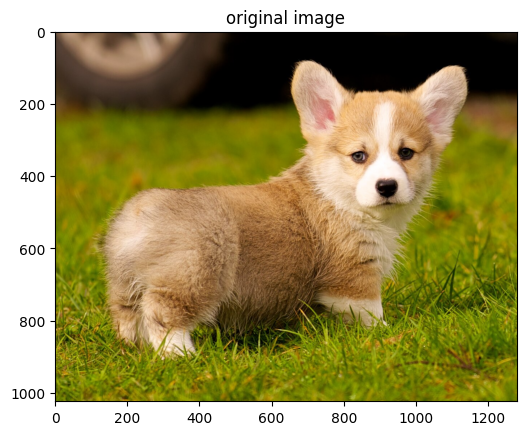

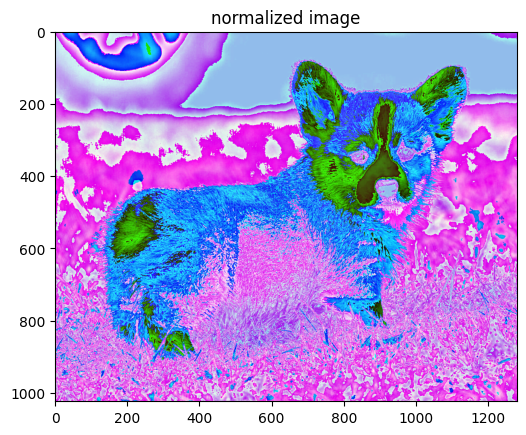

In [30]:
norm_img = norm_transform(korgi)
show_image(korgi, 'original image')
show_image(norm_img, 'normalized image')

<h2>Применение аугментации данных ко всему набору данных

In [31]:
from torchvision import datasets


T = transforms.Compose([
    transforms.RandomRotation(degrees=120),
    transforms.RandomHorizontalFlip(p=.2),
    transforms.RandomVerticalFlip(p=.2),
    transforms.ColorJitter(brightness=(.5, .5), contrast=1, saturation=0, hue=.4),
    transforms.ToTensor(),
    transforms.Normalize(mean=[.8], std=[.2])
])


train_dataset = datasets.MNIST(root='./SimpleNN', train=True, download=True, transform=transforms.ToTensor())
augmented_dataset = datasets.MNIST(root='./SimpleNN', train=True, download=True, transform=T)


100%|██████████| 9.91M/9.91M [00:04<00:00, 2.34MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 201kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]


In [32]:
train_dataset

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./SimpleNN
    Split: Train
    StandardTransform
Transform: ToTensor()

In [33]:
augmented_dataset

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./SimpleNN
    Split: Train
    StandardTransform
Transform: Compose(
               RandomRotation(degrees=[-120.0, 120.0], interpolation=nearest, expand=False, fill=0)
               RandomHorizontalFlip(p=0.2)
               RandomVerticalFlip(p=0.2)
               ColorJitter(brightness=(0.5, 0.5), contrast=(0.0, 2.0), saturation=None, hue=(-0.4, 0.4))
               ToTensor()
               Normalize(mean=[0.8], std=[0.2])
           )

In [34]:
train_dataset[0][0]

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [35]:
base_compose = transforms.Compose([
    transforms.ToPILImage()
])

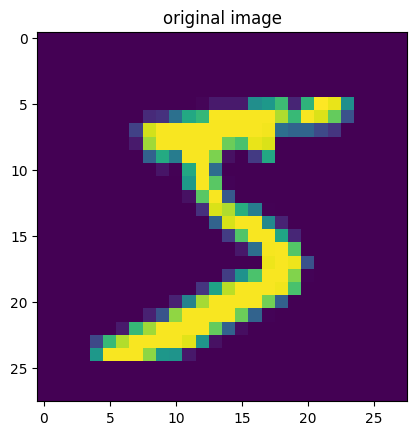

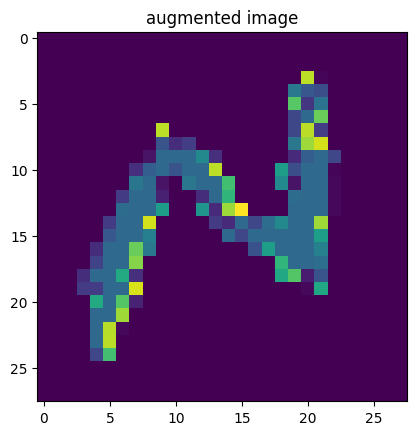

In [37]:
show_image(base_compose(train_dataset[0][0]), 'original image')
show_image(base_compose(augmented_dataset[0][0]), 'augmented image')

<center><h1>Практическое задание</h1></center>

1. Подобрать свой собственный набор данных
2. Выполнить на нём аугментации
3. Собрать единый набор данных из оригинального и аугментированного датасетов
4. Обучить простейшую CNN с ипользованием аугментированных данных